In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import random

from torchvision import transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision.models import efficientnet_b0, convnext_tiny

import cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

## Подготовка данных

In [2]:
train_df = pd.read_csv("ML9_dataset/Train.csv")
test_df = pd.read_csv("ML9_dataset/Test.csv")
sample = pd.read_csv("ML9_dataset/SampleSubmission.csv")

In [3]:
ran_rows = random.sample(range(0, train_df.shape[0]), 10)

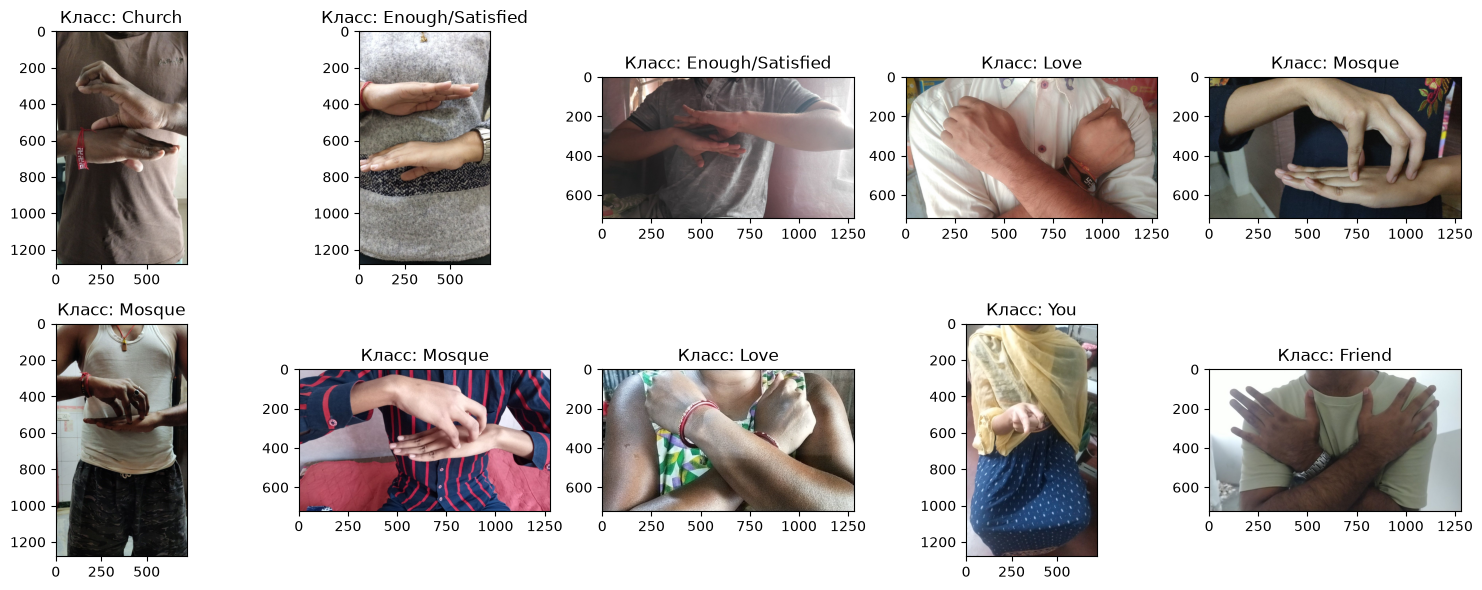

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax = ax.flatten()   
sizze = list()
for i, (ind, row) in enumerate(train_df.iloc[ran_rows].iterrows()):
    img_name = row['img_IDS']
    target = row['Label']
    
    img_path = os.path.join('ML9_dataset/Images/', img_name + '.jpg')

    if os.path.exists(img_path):
        img = Image.open(img_path)
        sizze.append(img.size)
        ax[i].imshow(img)
        ax[i].set_title(f"Класс: {target}")

plt.tight_layout()
plt.show()

In [5]:
sizze

[(720, 1280),
 (720, 1280),
 (1280, 720),
 (1280, 720),
 (1280, 720),
 (720, 1280),
 (1280, 720),
 (1280, 720),
 (720, 1280),
 (1280, 720)]

Тут я заметила, что изображения слишком большие, поэтому ниже применила Resize.

In [11]:
train_transform = transforms.Compose([
    transforms.Resize(32), # маленькая сторона 32
    transforms.RandomCrop(size=32), # обрезка размера 32
    transforms.RandomRotation(degrees=(-10, 10)), # поворот
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # ±20% яркость и контраст
    transforms.RandomPerspective(distortion_scale=0.1, p=0.1, fill=(0,0,0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(32),
    transforms.RandomCrop(size=32),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Это аугментации, те расширение данных за счет самих данных, но без использования лишней памяти.
\
Я использовала:
- обрезку, чтобы жест не всегда был в центре
- поворот, по горизонтали, но не сильный (от -10 до 10 градусов), чтобы не менялась суть жестов
- изменение свойств, таких как яркость и контростность
- перспеутива, чтобы жесты были под углом в 10% случаев

Все остальные преобразования нужны для дальнейшей корректной обработки данных.

In [6]:
train_data, val_data = train_test_split(train_df, test_size=0.33, stratify=train_df['Label']) # stratify - сохранение пропорций каждого класса    

In [8]:
# !find ML9_dataset/Images -name '*:Zone.Identifier' -delete

Я удалила все файлы, которые указывали на то, что файл скачан из интернета

### Создание своего датасета

In [7]:
class MyImageDataset(Dataset):
    def __init__(self, labels_df, img_dir, transform=None):
        self.img_labels = labels_df
        self.img_dir = img_dir
        self.transform = transform
 
    def __len__(self):
        return len(self.img_labels)
 
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0] + '.jpg')
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Не найдено: {img_path}")

        img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(img) # из numpy в PIL
        
        if self.transform:
            img = self.transform(img)

        target = int(self.img_labels.iloc[idx]['Label'])
        target = torch.tensor(target, dtype=torch.long)
        return img, target

In [8]:
le = LabelEncoder()
train_data['Label'] = le.fit_transform(train_data['Label'])
val_data['Label'] = le.transform(val_data['Label'])

In [9]:
# le.classes_
class_to_idx = {cls: i for i, cls in enumerate(le.classes_)}
print(class_to_idx)
print(len(class_to_idx))

{'Church': 0, 'Enough/Satisfied': 1, 'Friend': 2, 'Love': 3, 'Me': 4, 'Mosque': 5, 'Seat': 6, 'Temple': 7, 'You': 8}
9


In [12]:
train_dataset = MyImageDataset(train_data, img_dir='ML9_dataset/Images/', transform=train_transform)
val_dataset = MyImageDataset(val_data, img_dir='ML9_dataset/Images/', transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [13]:
images, labels = next(iter(train_loader))

print("Информация о DataLoader")
print("Тип images:", type(images))
print("Тип labels:", type(labels))
print("Форма images:", images.shape)
print("Форма labels:", labels.shape)
print("dtype images:", images.dtype)
print("dtype labels:", labels.dtype)
print("Первые 10 меток:", labels[:10])

Информация о DataLoader
Тип images: <class 'torch.Tensor'>
Тип labels: <class 'torch.Tensor'>
Форма images: torch.Size([32, 3, 32, 32])
Форма labels: torch.Size([32])
dtype images: torch.float32
dtype labels: torch.int64
Первые 10 меток: tensor([4, 4, 2, 8, 2, 7, 3, 2, 5, 2])


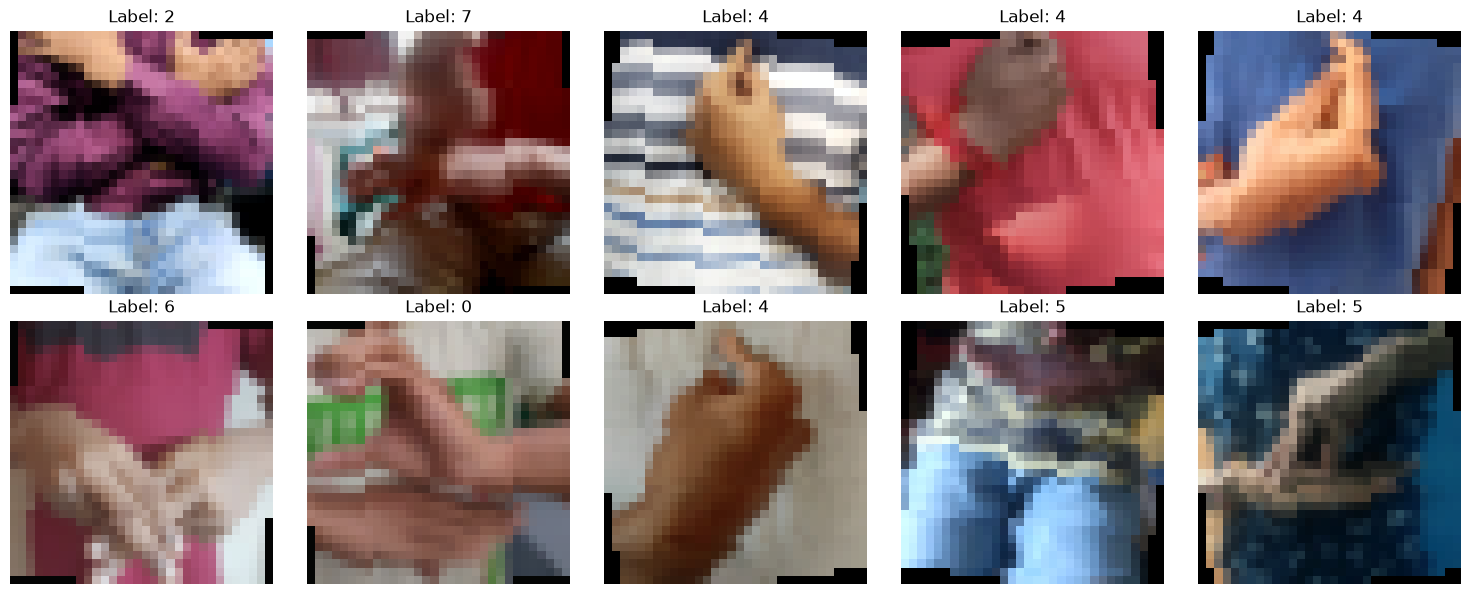

In [14]:
import matplotlib.pyplot as plt
import torch

# Берём один батч
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(10):
    img = images[i].permute(1, 2, 0).numpy()

    # приводим к виду, чтобы нрафики смогли отобразиться
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]
    img = img * std + mean
    img = img.clip(0, 1)  
    
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Функции

In [28]:
def train_network(model, train_loader, val_loader, loss_model, optimizer, device, epochs):
    for epoch in range(epochs):
        model.train()
        train_loop = tqdm(train_loader, leave=False)
        for batch_idx, (data, target) in enumerate(train_loop):
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = loss_model(output, target)
            loss.backward()
            optimizer.step()
            if batch_idx % 50 == 0:
                train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
        print(f"Ошибка: {loss.item()}")
    
        model.eval()
        test_loss = 0
        correct = 0
        all_probs = []
        all_targets = []
        
        with torch.no_grad():
            for data, target in val_loader:
                data, target = data.to(device), target.to(device)
                output = model(data)
                test_loss += loss_model(output, target).item() * data.size(0)
                pred = output.argmax(dim=1, keepdim=True)
                correct += pred.eq(target.view_as(pred)).sum().item()
    
                
                probs = torch.softmax(output, dim=1)
                all_probs.append(probs.cpu().numpy())
                all_targets.append(target.cpu().numpy())
    
        test_loss /= len(val_loader.dataset)
    
        all_probs = np.concatenate(all_probs)
        all_targets = np.concatenate(all_targets)
    
        roc_auc = roc_auc_score(
            all_targets,
            all_probs,
            multi_class='ovr',
            average='macro'
        )
        
        print('Val set (Epoch: {}): Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
            epoch+1, test_loss, correct, len(val_loader.dataset),
            100. * correct / len(val_loader.dataset), roc_auc))

### Сверточная нейронная сеть (CNN) LeNet-5

In [57]:
class LeNet5(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv = nn.Sequential(
            # (N, 3, 32, 32)
            nn.Conv2d(3, 32, (3, 3), padding='same', bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # (N, 32, 32, 32) -> (N, 32, 16, 16)
            nn.Dropout2d(0.2),

            nn.Conv2d(32, 64, 3, padding='same', bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # (N, 64, 16, 16) -> (N, 64, 8, 8)
            nn.Dropout2d(0.1),
        )

        self.flatten = nn.Flatten()
        self.act = nn.ReLU(inplace=True)

        self.layer_1 = nn.Linear(64 * 8 * 8, 32)
        self.layer_2 = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.layer_1(x)
        x = self.act(x)
        x = self.layer_2(x)
        return x

In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [45]:
model = LeNet5(9).to(device)

loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001) # , weight_decay=0.01

epochs = 20

In [46]:
for epoch in range(epochs):
    model.train()
    train_loop = tqdm(train_loader, leave=False)
    for batch_idx, (data, target) in enumerate(train_loop):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_model(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 50 == 0:
            train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
    print(f"Ошибка: {loss.item()}")

    model.eval()
    test_loss = 0
    correct = 0
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_model(output, target).item() * data.size(0)
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            
            probs = torch.softmax(output, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_targets.append(target.cpu().numpy())

    test_loss /= len(val_loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)

    roc_auc = roc_auc_score(
        all_targets,
        all_probs,
        multi_class='ovr',
        average='macro'
    )
    
    print('Test set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
        test_loss, correct, len(val_loader.dataset),
        100. * correct / len(val_loader.dataset), roc_auc))

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.227288007736206
Test set: Average loss: 2.1896, Accuracy: 278/2063 (13%), ROC AUC: 0.5607


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.2209413051605225
Test set: Average loss: 2.1763, Accuracy: 327/2063 (16%), ROC AUC: 0.5957


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.2118680477142334
Test set: Average loss: 2.1670, Accuracy: 365/2063 (18%), ROC AUC: 0.6180


... (30 outputs left out)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.0133378505706787
Test set: Average loss: 1.7568, Accuracy: 745/2063 (36%), ROC AUC: 0.7983


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.786789059638977
Test set: Average loss: 1.7398, Accuracy: 771/2063 (37%), ROC AUC: 0.8023


На 11 эпохе был достигнут минимальный по заданию ROC AUC: 0.7577, а по истечению 20 эпох ROC AUC возрос до 0.8023\
\
Также видно, что после 12 эпохи метрика начала гораздо медленнее увеличиваться, скорее всего для её быстрого роста после ~0,77 нужно менять параметры.

In [ ]:
# model.train()
# for epoch in range(epochs):
#     1. Тренировка модели
#     train_loop = tqdm(train_loader, leave=False)
#     train_loss = 0.0
#     train_correct = 0
#     train_total = 0

#     for x, target in train_loop:
#         x = x.to(device)
#         target = target.to(device)

#         # - Прямой проход + расчёт ошибки модели
#         pred = model(x)
#         loss = loss_model(pred, target)

#         # - Обратный проход
#         optimizer.zero_grad()
#         loss.backward()
#         # - Шаг оптимизации
#         optimizer.step()

#         train_loss += loss.item() * x.size(0)
#         train_correct += (pred.argmax(1) == target).sum().item()
#         train_total += x.size(0)

#         train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]")

#     avg_train_loss = train_loss / train_total
#     train_acc = train_correct / train_total
    
#     val_loss = 0.0
#     val_correct = 0
#     val_total = 0
#     4. Проверка модели (валидация)
#     model.eval()
#     with torch.no_grad():  # запрещаем вычисление градиента внутри with
#         for x, targets in val_loader:
#             x = x.to(device)
#             targets = targets.to(device)

#             # - Прямой проход + расчёт ошибки модели
#             pred = model(x)
#             loss = loss_model(pred, targets)

#             val_loss += loss.item() * x.size(0)
#             val_correct += (pred.argmax(1) == targets).sum().item()
#             val_total += x.size(0)`

#     avg_val_loss = val_loss / val_total
#     val_acc = val_correct / val_total

#     print(f"Epoch {epoch+1}/{epochs} | "
#           f"train_loss={avg_train_loss:.4f} train_acc={train_acc:.4f} | "
#           f"val_loss={avg_val_loss:.4f} val_acc={val_acc:.4f}")            

### Подготовка данных под  ResNet18 

In [37]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

# Меняем последний слой под свои данные
model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

Без weights='IMAGENET1K_V1' модель за 5 4 эпохи достигала окло 0,72, этого недостаточно, поэтому добавила параметр с предобученными весами.

In [38]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001)

epochs = 5

Нужно убрать `epoch` при следующем запуске

In [39]:
train_network(model, train_loader, val_loader, loss_model, optimizer, device, epoch, epochs)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.4209123849868774
Val set (Epoch: 1): Average loss: 1.6380, Accuracy: 843/2063 (41%), ROC AUC: 0.8176


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.1845797300338745
Val set (Epoch: 2): Average loss: 1.4360, Accuracy: 996/2063 (48%), ROC AUC: 0.8662


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.180349588394165
Val set (Epoch: 3): Average loss: 1.2813, Accuracy: 1117/2063 (54%), ROC AUC: 0.8939


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 0.9909782409667969
Val set (Epoch: 4): Average loss: 1.1899, Accuracy: 1183/2063 (57%), ROC AUC: 0.9095


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.0454764366149902
Val set (Epoch: 5): Average loss: 1.1467, Accuracy: 1200/2063 (58%), ROC AUC: 0.9155


Заданный результат ROC AUC > 0.9 был достигнут за 4 эпохи. \
Скорее всего более быстрого результата можно достигуть, если уменьшить лр (это показывает пример ниже).

### Тестирование других моделей

#### EfficientNet (b0)

In [24]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = efficientnet_b0(weights='IMAGENET1K_V1')

model.classifier[1] = nn.Linear(model.classifier[1].in_features, 9)
model = model.to(device)

In [25]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.001)

epochs = 5

In [29]:
train_network(model, train_loader, val_loader, loss_model, optimizer, device, epochs)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.8252980709075928
Val set (Epoch: 1): Average loss: 1.6766, Accuracy: 803/2063 (39%), ROC AUC: 0.8144


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.0918941497802734
Val set (Epoch: 2): Average loss: 1.3423, Accuracy: 1062/2063 (51%), ROC AUC: 0.8856


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.3886057138442993
Val set (Epoch: 3): Average loss: 1.2482, Accuracy: 1118/2063 (54%), ROC AUC: 0.9036


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.284050703048706
Val set (Epoch: 4): Average loss: 1.1087, Accuracy: 1272/2063 (62%), ROC AUC: 0.9243


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 0.9901484847068787
Val set (Epoch: 5): Average loss: 1.0304, Accuracy: 1314/2063 (64%), ROC AUC: 0.9308


Отметка ROC AUC > 0.9 была достигнута за 2 эпохи.

#### ConvNeXt-Tiny

При выборе между ConvNeXt-Tiny и ConvNeXt-Small, я выбрала 1, потому что он больше подходит для моих данных, а конкретно обрабатывает меньше параметров (~28млн, тратит меньше памяти и на 8000 картинок низкий риск переобучения)

In [32]:
model = convnext_tiny(weights='IMAGENET1K_V1')
model.classifier

Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=1000, bias=True)
)

In [34]:
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 9)
model = model.to(device)

In [35]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.01)

epochs = 5

In [36]:
train_network(model, train_loader, val_loader, loss_model, optimizer, device, epochs)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.1755716800689697
Val set (Epoch: 1): Average loss: 2.2033, Accuracy: 229/2063 (11%), ROC AUC: 0.4956


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.1675126552581787
Val set (Epoch: 2): Average loss: 2.2044, Accuracy: 229/2063 (11%), ROC AUC: 0.5110


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.172974109649658
Val set (Epoch: 3): Average loss: 2.2060, Accuracy: 229/2063 (11%), ROC AUC: 0.4928


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.328721761703491
Val set (Epoch: 4): Average loss: 2.2046, Accuracy: 229/2063 (11%), ROC AUC: 0.4880


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.193065881729126
Val set (Epoch: 5): Average loss: 2.2098, Accuracy: 229/2063 (11%), ROC AUC: 0.5003


Видно, что lr=0.01 слишком мал, чтобы модель быстро и правильно обучалась.

#### Le_Net-18 улучшение результатов

In [43]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

# Меняем последний слой под свои данные
model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

In [44]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.001)

epochs = 5
train_network(model, train_loader, val_loader, loss_model, optimizer, device, epochs)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.8593953847885132
Val set (Epoch: 1): Average loss: 1.6146, Accuracy: 878/2063 (43%), ROC AUC: 0.8406


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.2746360301971436
Val set (Epoch: 2): Average loss: 1.4032, Accuracy: 960/2063 (47%), ROC AUC: 0.8789


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.39296293258667
Val set (Epoch: 3): Average loss: 1.2780, Accuracy: 1094/2063 (53%), ROC AUC: 0.9023


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.1353991031646729
Val set (Epoch: 4): Average loss: 1.2869, Accuracy: 1065/2063 (52%), ROC AUC: 0.9031


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.2253199815750122
Val set (Epoch: 5): Average loss: 1.1730, Accuracy: 1185/2063 (57%), ROC AUC: 0.9162


Видно, что модель обучается лучше, чем в предыдущий раз. Показатель достиг 0,9 на 3 эпохе, благодаря увеличению learning rate.

### Aугментации MixUp и CutMix

Наложение одного изображения на другое, чтобы при неопределенности между классами модель была устойчевее.

In [54]:
def mixup_data(images, labels, alpha=0.2):
    # бета-распределение - (0,05; 0,95) сколько пикселей смешивается из разных классов (при alpha ~0,2)
    lamb = np.random.beta(alpha, alpha)
    
    # перестановка картинок внутри батча
    batch_size = images.size(0)
    index = torch.randperm(batch_size, device=images.device)
    
    # перемешивае изображений
    mixed_images = lamb * images + (1 - lamb) * images[index]
    
    # правильные ответы
    labels_a = labels
    labels_b = labels[index]
    return mixed_images, labels_a, labels_b, lamb

# функция потерь
def mixup_cutmix_criterion(criterion, pred, labels_a, labels_b, lamb):
    return lamb * criterion(pred, labels_a) + (1 - lamb) * criterion(pred, labels_b)

Вставляет фрагмент в другуб картинку, чтобы модель понимала не только положение пальцев, но и кисти, например.

In [51]:
def cutmix_data(images, labels, alpha=1.0):
    # при alpha=1, lamb случайна (0,5; 0,5) или (0,3; 0,7)
    lamb = np.random.beta(alpha, alpha)
    batch_size = images.size(0)
    index = torch.randperm(batch_size, device=images.device)
    
    _, _, H, W = images.size()
    
    # размер вырезаемого прямоугольника
    cut_ratio = np.sqrt(1.0 - lamb)
    cut_h = int(H * cut_ratio)
    cut_w = int(W * cut_ratio)
    
    # случайная точка на изображении для центра 
    cy = np.random.randint(H)
    cx = np.random.randint(W)
    
    # границы вырезки
    y1 = np.clip(cy - cut_h // 2, 0, H)
    y2 = np.clip(cy + cut_h // 2, 0, H)
    x1 = np.clip(cx - cut_w // 2, 0, W)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    
    # вставка прямоугольника
    mixed_images = images.clone()
    mixed_images[:, :, y1:y2, x1:x2] = images[index, :, y1:y2, x1:x2]
    
    # пересчитываем lamb для вырезанной части
    lamb = 1 - ((y2 - y1) * (x2 - x1) / (H * W))
    
    labels_a = labels
    labels_b = labels[index]
    
    return mixed_images, labels_a, labels_b, lamb


### Применение MixUp и CutMix на модели

In [109]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

In [110]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.002)

epochs = 5
use_mixup = False
use_cutmix = False
mixup_alpha = 0.2
cutmix_alpha = 1.0

In [111]:
for epoch in range(epochs):
    model.train()
    train_loop = tqdm(train_loader, leave=False)
    
    for batch_idx, (data, target) in enumerate(train_loop):
        data, target = data.to(device), target.to(device)
        
        r = np.random.rand()
        aug_type = None
        
        if r < 0.15:
            if use_mixup and use_cutmix:
                aug_type = 'mixup' if np.random.rand() < 0.5 else 'cutmix'
            elif use_mixup:
                aug_type = 'mixup'
            elif use_cutmix:
                aug_type = 'cutmix'
        
        if aug_type == 'mixup':
            data, target_a, target_b, lamb = mixup_data(data, target, mixup_alpha)
        elif aug_type == 'cutmix':
            data, target_a, target_b, lamb = cutmix_data(data, target, cutmix_alpha)
        
        optimizer.zero_grad()
        output = model(data)
        
        # Вычисляем loss с учётом аугментации
        if aug_type is not None:
            loss = mixup_cutmix_criterion(loss_model, output, target_a, target_b, lamb)
        else:
            loss = loss_model(output, target)
        
        loss.backward()
        optimizer.step()
        
        if batch_idx % 50 == 0:
            train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
    
    print(f"Ошибка: {loss.item()}")

    model.eval()
    test_loss = 0
    correct = 0
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_model(output, target).item() * data.size(0)
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
            
            probs = torch.softmax(output, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_targets.append(target.cpu().numpy())

    test_loss /= len(val_loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)

    roc_auc = roc_auc_score(
        all_targets,
        all_probs,
        multi_class='ovr',
        average='macro'
    )
    
    print('Val set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
        test_loss, correct, len(val_loader.dataset),
        100. * correct / len(val_loader.dataset), roc_auc))

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.8171372413635254
Val set: Average loss: 2.2973, Accuracy: 547/2063 (27%), ROC AUC: 0.7454


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.865965485572815
Val set: Average loss: 1.9380, Accuracy: 589/2063 (29%), ROC AUC: 0.7756


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.418584942817688
Val set: Average loss: 1.5979, Accuracy: 871/2063 (42%), ROC AUC: 0.8441


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.3563268184661865
Val set: Average loss: 1.4495, Accuracy: 974/2063 (47%), ROC AUC: 0.8752


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.880820393562317
Val set: Average loss: 1.3223, Accuracy: 1047/2063 (51%), ROC AUC: 0.8947


Нужно отметить, что mixup и cutmix изменяют Accuracy и это четко видно на больших эпохах.\
В предыдущем цикле за 5 эпох Accuracy был прогресс на 14%.\
В этот же раз за 5 эпох Accuracy +25%

### Разбор бонуски

In [20]:
tta_transforms = [
    # Поворот на 10°
    transforms.Compose([
        transforms.Resize(32),
        transforms.RandomCrop(size=32),
        transforms.RandomRotation(degrees=(10, 10)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    # Поворот на -10°
    transforms.Compose([
        transforms.Resize(32),
        transforms.RandomCrop(size=32),
        transforms.RandomRotation(degrees=(-10, -10)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
]

tta_datasets = [
    MyImageDataset(val_data, img_dir='ML9_dataset/Images/', transform=tta_transform)
    for tta_transform in tta_transforms
]

tta_loaders = [
    DataLoader(dataset, batch_size=32, shuffle=False)
    for dataset in tta_datasets
]

In [31]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001)

epochs = 5

#### С TTA

In [32]:
for epoch in range(epochs):
    model.train()
    train_loop = tqdm(train_loader, leave=False)
    for batch_idx, (data, target) in enumerate(train_loop):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_model(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 50 == 0:
            train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
    print(f"Ошибка: {loss.item()}")

    model.eval()
    test_loss = 0
    correct = 0
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        tta_iters = [iter(loader) for loader in tta_loaders]
        
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_model(output, target).item() * data.size(0)
            
            probs = torch.softmax(output, dim=1)

            # тут замена для тта
            for tta_iter in tta_iters:
                tta_data, _ = next(tta_iter)
                tta_data = tta_data.to(device)
                tta_output = model(tta_data)
                probs += torch.softmax(tta_output, dim=1)
            probs = probs / (1 + len(tta_loaders))
            
            pred = probs.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
            
            all_probs.append(probs.cpu().numpy())
            all_targets.append(target.cpu().numpy())

    test_loss /= len(val_loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)

    roc_auc = roc_auc_score(
        all_targets,
        all_probs,
        multi_class='ovr',
        average='macro'
    )
    
    print('Val set [epoch {}]: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
        epoch, test_loss, correct, len(val_loader.dataset),
        100. * correct / len(val_loader.dataset), roc_auc))

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.9045658111572266
Val set [epoch 0]: Average loss: 1.6460, Accuracy: 970/2063 (47%), ROC AUC: 0.8530


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.8086886405944824
Val set [epoch 1]: Average loss: 1.3962, Accuracy: 1094/2063 (53%), ROC AUC: 0.8990


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.1903663873672485
Val set [epoch 2]: Average loss: 1.2652, Accuracy: 1226/2063 (59%), ROC AUC: 0.9196


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.3735156059265137
Val set [epoch 3]: Average loss: 1.2117, Accuracy: 1276/2063 (62%), ROC AUC: 0.9278


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 0.8172141313552856
Val set [epoch 4]: Average loss: 1.1239, Accuracy: 1343/2063 (65%), ROC AUC: 0.9370


`probs = probs / (1 + len(tta_loaders))` - эта строка усреднения результатов. Выбирается та, которая подходит по всем предсказаниям.

#### Без TTA

In [29]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001)

epochs = 5

In [30]:
for epoch in range(epochs):
    model.train()
    train_loop = tqdm(train_loader, leave=False)
    for batch_idx, (data, target) in enumerate(train_loop):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_model(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 50 == 0:
            train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
    print(f"Ошибка: {loss.item()}")

    model.eval()
    test_loss = 0
    correct = 0
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_model(output, target).item() * data.size(0)
            
            probs = torch.softmax(output, dim=1)
            
            pred = probs.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
            
            all_probs.append(probs.cpu().numpy())
            all_targets.append(target.cpu().numpy())

    test_loss /= len(val_loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)

    roc_auc = roc_auc_score(
        all_targets,
        all_probs,
        multi_class='ovr',
        average='macro'
    )
    
    print('Val set [epoch {}]: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
        epoch, test_loss, correct, len(val_loader.dataset),
        100. * correct / len(val_loader.dataset), roc_auc))

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.0215108394622803
Val set [epoch 0]: Average loss: 1.6745, Accuracy: 804/2063 (39%), ROC AUC: 0.8078


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.6836440563201904
Val set [epoch 1]: Average loss: 1.4227, Accuracy: 989/2063 (48%), ROC AUC: 0.8660


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.438124418258667
Val set [epoch 2]: Average loss: 1.3206, Accuracy: 1051/2063 (51%), ROC AUC: 0.8867


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.232211947441101
Val set [epoch 3]: Average loss: 1.2004, Accuracy: 1169/2063 (57%), ROC AUC: 0.9062


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.3060330152511597
Val set [epoch 4]: Average loss: 1.1202, Accuracy: 1244/2063 (60%), ROC AUC: 0.9182


С помошбю прогонки через модель несколько раз и аугментаций получились лучшие результаты.\
Применение TTA увеличило качество модели. Выигрыш составил: ROC AUC +0.0188.\
Чтобы не долго ждать я остановила развитие модели на 5 эпохе, но чем дольше обучаласб модель, тем быстрее мы пришли к результату с наименьшим числом ошибок.

### Тестовая выборка

In [50]:
class TestDataset(Dataset):
    def __init__(self, labels_df, img_dir, transform=None):
        self.img_labels = labels_df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0] + '.jpg')
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Не найдено: {img_path}")

        img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(img)

        if self.transform:
            img = self.transform(img)

        return img

In [51]:
model.eval()
all_test_probs = []

with torch.no_grad():
    for batches in zip(*test_tta_loaders):
        probs = 0
        for data in batches:
            data = data.to(device)
            output = model(data)
            probs = probs + torch.softmax(output, dim=1)
        probs = probs / len(batches)
        all_test_probs.append(probs.cpu().numpy())

all_test_probs = np.concatenate(all_test_probs)

all_test_ids = test_df['img_IDS'].astype(str).tolist()

submission = sample.copy()
for i, img_id in enumerate(all_test_ids):
    mask = submission['img_IDS'] == img_id
    for j, cls_name in enumerate(le.classes_):
        submission.loc[mask, cls_name] = all_test_probs[i, j]

submission.to_csv('test_tta.csv', index=False)
print(submission.head(10))

            img_IDS    Church  Enough/Satisfied    Friend      Love        Me  \
0  ImageID_USRB8QNG  0.262112          0.093607  0.036460  0.014882  0.017891   
1  ImageID_SZ8D1ZJI  0.419657          0.499462  0.004377  0.001156  0.004742   
2  ImageID_4OJO2F8J  0.030937          0.046667  0.048258  0.049246  0.008319   
3  ImageID_IEE4XV0B  0.026091          0.009680  0.003948  0.002851  0.003625   
4  ImageID_BP0O0WZ9  0.021586          0.020663  0.047878  0.047814  0.396655   
5  ImageID_M0V58H3K  0.175210          0.363622  0.007169  0.006423  0.093795   
6  ImageID_R87BQKKT  0.001027          0.002487  0.410112  0.558720  0.006854   
7  ImageID_MX5UE68W  0.003240          0.005655  0.472278  0.469952  0.013411   
8  ImageID_3AAK0323  0.012646          0.008580  0.105477  0.115848  0.470377   
9  ImageID_F3G4F52P  0.027065          0.019616  0.030027  0.080895  0.183559   

     Mosque      Seat    Temple       You  
0  0.169669  0.016691  0.363366  0.025322  
1  0.023381  0.00326

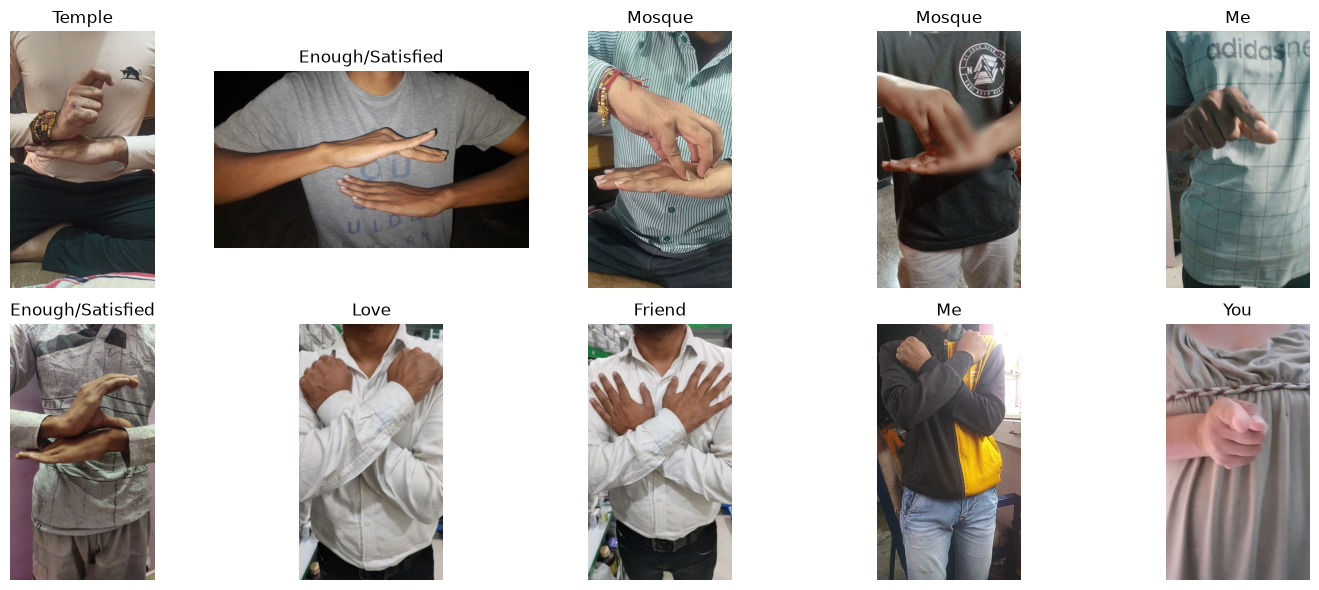

In [53]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(10):
    img_id = test_df['img_IDS'].iloc[i]
    img = plt.imread(f'ML9_dataset/Images/{img_id}.jpg')

    pred_idx = all_test_probs[i].argmax()
    pred_class = le.classes_[pred_idx]

    axes[i].imshow(img)
    axes[i].set_title(pred_class)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

!git add ml9.ipynb
!git commit -m "Реализация MixUp и CutMix"
!git push origin develop

!git add ML9_dataset/Images/
!git commit -m "Данные"
!git push origin develop